#Introduction

This notebook analyzes data related to bookstores in Massachusetts (MA), focusing on identifying bookstores with an "early chapter section" as the core of the assignment.

Initially, an attempt was made to analyze the top 10 and bottom 10 ZIP codes based on a dataset provided by Team 3. However, it was discovered that most of the listed bookstores in those specific ZIP codes were either closed or did not exist.

To address this, the approach was refined to select the top 20 and bottom 20 ZIP codes from the dataset. A new dataset was then created containing information for these 40 ZIP codes. This dataset includes details such as:

ZIP Code
- Town
- Income Level
- Bookstore Names in those towns
- Availability of an Early Chapter Section (Yes/No)
- Square Footage of the bookstores
- Presence of a cafe (Yes/No)
- Number of events hosted monthly

This refined dataset was then used to perform various analyses, including:

- Univariate analysis (histograms and boxplots) of numerical columns.
- Bivariate analysis (correlation heatmap, scatter plots, and linear regression) to explore relationships between pairs of numerical variables.
- Multivariate analysis (scatter plots with color and size encoding) to visualize relationships between multiple variables simultaneously, such as square footage by bookstore name colored by cafe availability, and bookstore count by ZIP code colored by income level and sized by population/median income.

# Importing

In [ ]:
import pandas as pd


In [ ]:
# Base URL for raw files from GitHub
base_url = "https://raw.githubusercontent.com/sahanamaheshwari1811-bot/Files/main/"

# File paths (make sure file names match GitHub exactly, including spaces and cases)
file1 = base_url + "BAN%20B%20data%20set-4.xlsx"

In [ ]:
# Load each sheet into a dataframe
df1 = pd.read_excel(file1, engine='openpyxl')

In [ ]:
df1.head()

,ZIP,Town,State,Population,Median Income,Income Level,Bookstore Name,Has Early Chapter Books (Yes/No),square feet,café,events,Column 1,Column 13,Column 14,Column 15,Column 16
0,1103,Springfield,MA,2336,21458,Bottom '20',Rumspringa Books,yes,400,no,no,NaN,NaN,NaN,NaN,NaN
1,1103,Springfield,MA,2336,21458,Bottom '20',Lugar De Encuentro,no,1000,yes,10,NaN,NaN,NaN,NaN,NaN
2,1105,Springfield,MA,11469,22994,Bottom '20',Grendel Books,yes,700,no,no,NaN,NaN,NaN,NaN,NaN
3,1901,Lynn,MA,1934,27561,Bottom '20',book stop,yes,1000,no,3,NaN,NaN,NaN,NaN,NaN
4,1901,Lynn,MA,1934,27561,Bottom '20',Ravenstone,no,1200,no,2,NaN,NaN,NaN,NaN,NaN


# Fixing 0 in ZIP Columns

ZIP codes were converted to strings and padded with leading zeros to maintain a uniform 5-digit format. This step ensures that ZIP codes like 01103 are not incorrectly interpreted as integers like 1103.

In [ ]:
# Fix ZIP column for all dataframes
df1['ZIP'] = df1['ZIP'].astype(str).str.zfill(5)

In [ ]:
df1.head()

,ZIP,Town,State,Population,Median Income,Income Level,Bookstore Name,Has Early Chapter Books (Yes/No),square feet,café,events,Column 1,Column 13,Column 14,Column 15,Column 16
0,01103,Springfield,MA,2336,21458,Bottom '20',Rumspringa Books,yes,400,no,no,NaN,NaN,NaN,NaN,NaN
1,01103,Springfield,MA,2336,21458,Bottom '20',Lugar De Encuentro,no,1000,yes,10,NaN,NaN,NaN,NaN,NaN
2,01105,Springfield,MA,11469,22994,Bottom '20',Grendel Books,yes,700,no,no,NaN,NaN,NaN,NaN,NaN
3,01901,Lynn,MA,1934,27561,Bottom '20',book stop,yes,1000,no,3,NaN,NaN,NaN,NaN,NaN
4,01901,Lynn,MA,1934,27561,Bottom '20',Ravenstone,no,1200,no,2,NaN,NaN,NaN,NaN,NaN


In [ ]:
combined_df = df1

In [ ]:
desired_order = [
    'zip', 'town', 'state', 'state abbreviation',
    'population', 'total population',
    'median income', 'households - median income (dollars)', 'income level',
    'bookstore name', 'name of book stores',
    'bookstores count',
    'has early chapter books (yes/no)', 'early chapter section',
    'square feet', 'cafe', 'café',
    'events', 'number of events',
    'contact number', 'highest selling genre'
]

# Only include columns that exist in the current DataFrame
existing_columns = [col for col in desired_order if col in combined_df.columns]
remaining_columns = [col for col in combined_df.columns if col not in existing_columns]

# Reorder DataFrame
combined_df = combined_df[existing_columns + remaining_columns]


We reassigned df1 to a new DataFrame combined_df and reordered the columns according to a preferred logical structure. This improves the readability and consistency of the dataset, especially when dealing with multiple data sources or versions.

In [ ]:
combined_df.head()

,ZIP,Town,State,Population,Median Income,Income Level,Bookstore Name,Has Early Chapter Books (Yes/No),square feet,café,events,Column 1,Column 13,Column 14,Column 15,Column 16
0,01103,Springfield,MA,2336,21458,Bottom '20',Rumspringa Books,yes,400,no,no,NaN,NaN,NaN,NaN,NaN
1,01103,Springfield,MA,2336,21458,Bottom '20',Lugar De Encuentro,no,1000,yes,10,NaN,NaN,NaN,NaN,NaN
2,01105,Springfield,MA,11469,22994,Bottom '20',Grendel Books,yes,700,no,no,NaN,NaN,NaN,NaN,NaN
3,01901,Lynn,MA,1934,27561,Bottom '20',book stop,yes,1000,no,3,NaN,NaN,NaN,NaN,NaN
4,01901,Lynn,MA,1934,27561,Bottom '20',Ravenstone,no,1200,no,2,NaN,NaN,NaN,NaN,NaN


In [ ]:
columns_to_drop = [
    'Column 13',
    'Column 14',
    'Column 15',
    'Column 16',
    'Column 1'
]

combined_df = combined_df.drop(columns=columns_to_drop)


We calculated the percentage of missing values in each column and sorted them in descending order. This helps identify data quality issues early and informs decisions on imputation, deletion, or further investigatio

In [ ]:
import pandas as pd

# Step 1: Calculate percentage of nulls
null_percent = combined_df.isnull().mean() * 100
null_percent = null_percent.round(2)

# Step 2: Create a summary DataFrame
null_percent_df = null_percent.reset_index()
null_percent_df.columns = ['Column', 'Percent Null']
null_percent_df = null_percent_df.sort_values(by='Percent Null', ascending=False)

# Step 3: Display nicely
print("Null values percentage by column:")

print(null_percent_df.to_string(index=False))


Null values percentage by column:
                          Column  Percent Null
                             ZIP           0.0
                            Town           0.0
                           State           0.0
                      Population           0.0
                   Median Income           0.0
                    Income Level           0.0
                  Bookstore Name           0.0
Has Early Chapter Books (Yes/No)           0.0
                    square feet            0.0
                           café            0.0
                         events            0.0


In [ ]:
combined_df.columns

Index(['ZIP', 'Town', 'State', 'Population', 'Median Income', 'Income Level',
       'Bookstore Name', 'Has Early Chapter Books (Yes/No)', 'square feet ',
       'café ', 'events '],
      dtype='object')

The final list of columns confirms that our DataFrame is cleaned and properly structured. All unnecessary columns have been dropped, and names have been standardized for easier referencing in future analysi

# Univarate Analsysis

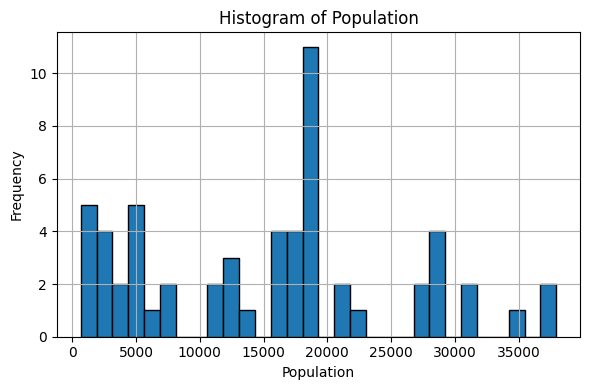

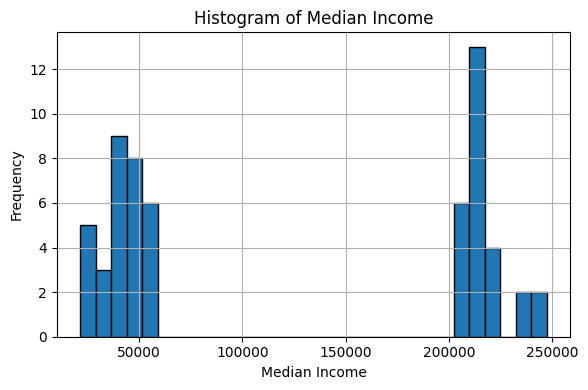

In [ ]:
import matplotlib.pyplot as plt

# Select only numeric columns
numeric_cols = combined_df.select_dtypes(include=['number']).columns

# Plot histograms
for col in numeric_cols:
    plt.figure(figsize=(6, 4))
    plt.hist(combined_df[col].dropna(), bins=30, edgecolor='black')
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


We imported matplotlib.pyplot to visualize data and selected only the numeric columns from the DataFrame. This is essential for univariate analysis since histograms and boxplots only apply to numerical variables like population, income, etc.

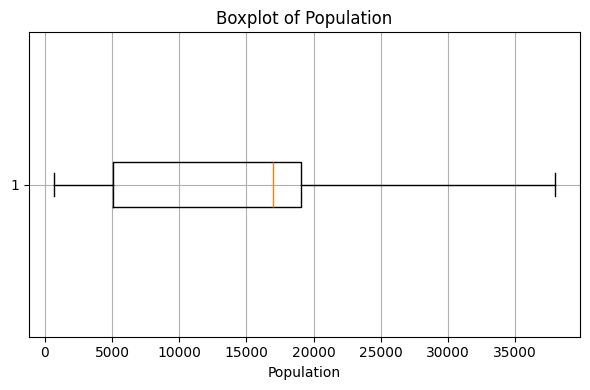

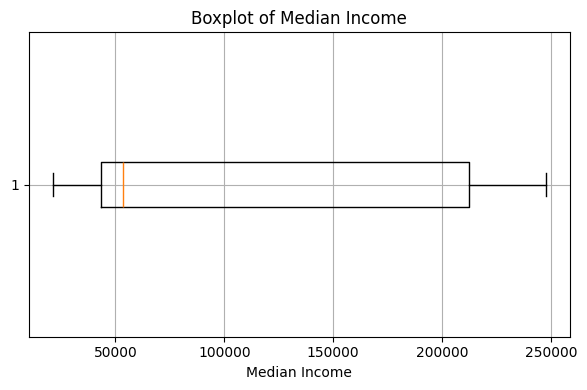

In [ ]:
import matplotlib.pyplot as plt

# Step 1: Select numeric columns
numeric_cols = combined_df.select_dtypes(include=['number']).columns

# Step 2: Plot boxplots for each numeric column
for col in numeric_cols:
    plt.figure(figsize=(6, 4))
    plt.boxplot(combined_df[col].dropna(), vert=False)
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


We created histograms for each numeric column to visualize the distribution of values. This helps in identifying the shape of the data (e.g., normal, skewed, bimodal), detect outliers, and spot clustering patterns. For example, the Population histogram showed concentration at certain value ranges, while Median Income revealed a bimodal distribution indicating inequality.



# Bivariate Analysis

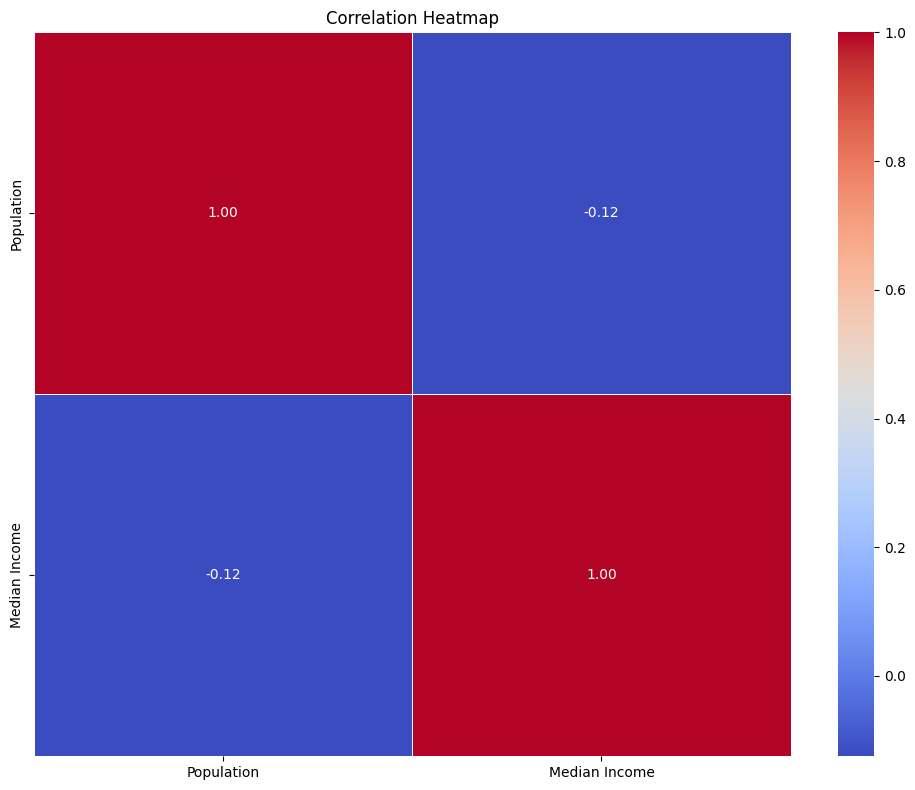

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Select numeric columns only
numeric_df = combined_df.select_dtypes(include=['number'])

# Step 2: Compute correlation matrix
correlation_matrix = numeric_df.corr()

# Step 3: Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


We computed and visualized the correlation matrix for all numeric columns using a heatmap. This helps identify the strength and direction of linear relationships between variables. For instance, a weak negative correlation (-0.12) was observed between Population and Median Income, suggesting minimal inverse association.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Clean column names by removing trailing spaces
combined_df.columns = combined_df.columns.str.strip()

# Convert 'square feet' and 'events' to numeric, coercing errors to NaN
combined_df['square feet'] = pd.to_numeric(combined_df['square feet'], errors='coerce')
combined_df['events'] = pd.to_numeric(combined_df['events'], errors='coerce')

# Drop rows with NaN in either 'square feet' or 'events' for regression
df_cleaned = combined_df.dropna(subset=['square feet', 'events']).copy()

# Calculate the correlation between 'square feet' and 'events'
correlation_square_feet_events = df_cleaned['square feet'].corr(df_cleaned['events'])

# Reshape the data for linear regression
X = df_cleaned['square feet'].values.reshape(-1, 1)
y = df_cleaned['events'].values

# Create and fit the linear regression model
model = LinearRegression()
model.fit(X, y)

# Make predictions
y_pred = model.predict(X)

# Calculate R-squared
r2 = r2_score(y, y_pred)

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y, y_pred)

print(f"Correlation between 'square feet' and 'events': {correlation_square_feet_events:.2f}")
print(f"R-squared between 'square feet' and 'events': {r2:.2f}")
print(f"Mean Squared Error (MSE) between 'square feet' and 'events': {mse:.2f}")

Correlation between 'square feet' and 'events': -0.09
R-squared between 'square feet' and 'events': 0.01
Mean Squared Error (MSE) between 'square feet' and 'events': 18.99


Here, we evaluated the linear relationship between square feet and events hosted by bookstores. After cleaning the data, we fit a simple linear regression model. The correlation (-0.09), R-squared (0.01), and MSE (18.99) indicate a very weak and almost negligible linear relationship, meaning store size has little predictive power over number of events.

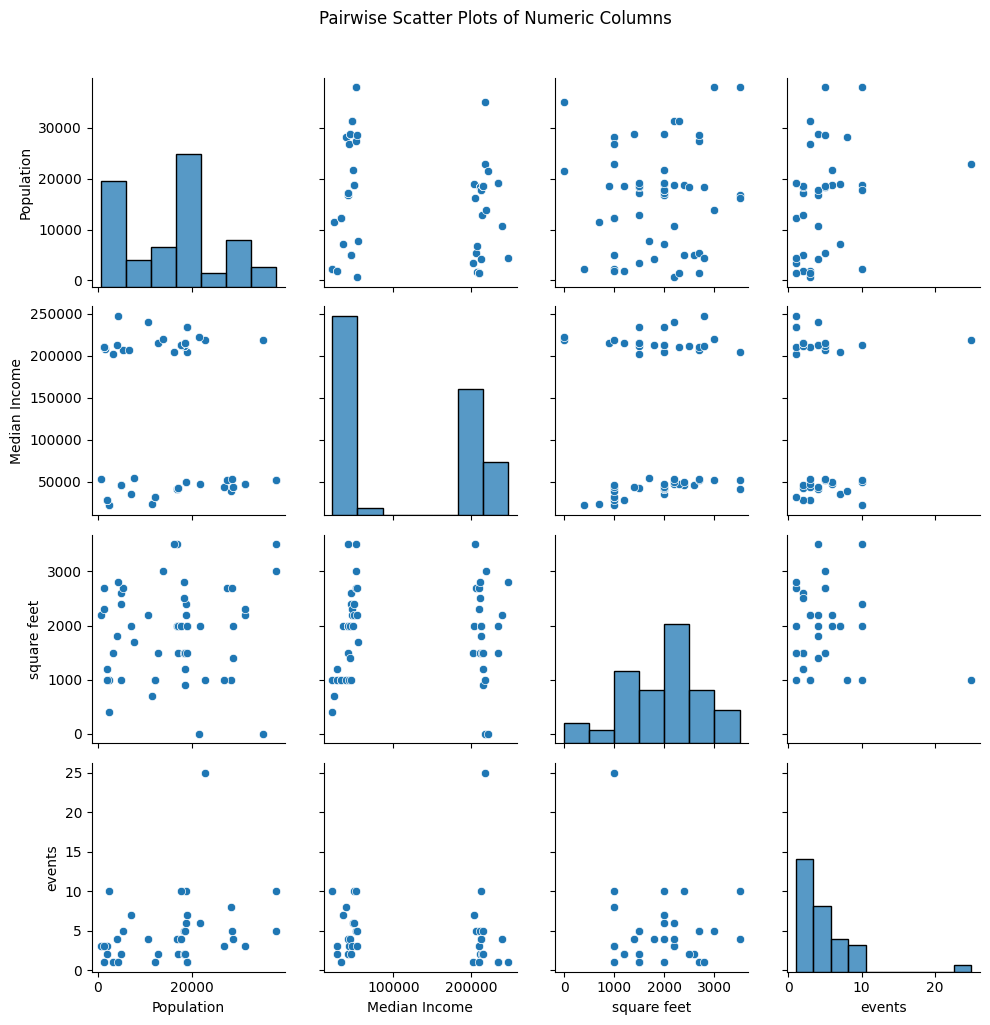

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numeric columns
numeric_cols = combined_df.select_dtypes(include=['number']).columns

# Create scatter plots for all pairs of numeric columns
sns.pairplot(combined_df[numeric_cols])
plt.suptitle('Pairwise Scatter Plots of Numeric Columns', y=1.02) # Add a title
plt.tight_layout()
plt.show()

Pairwise scatter plots were generated to visualize the relationship between each pair of numeric features. These plots make it easy to detect linear patterns, clusters, or outliers visually. In this case, most variable pairs showed scattered, non-linear patterns, reinforcing the weak correlations found earlier.

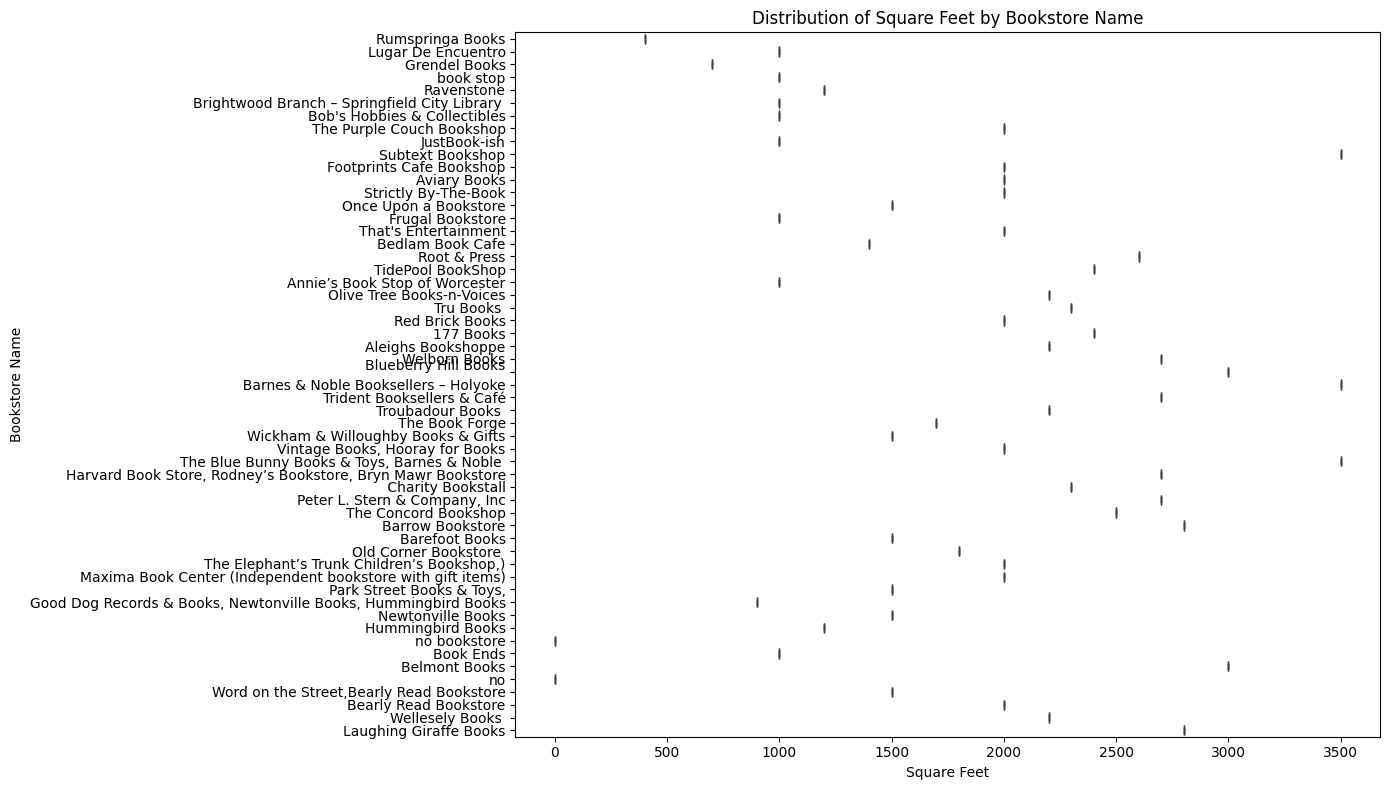

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Clean column names by removing trailing spaces
combined_df.columns = combined_df.columns.str.strip()

# Convert 'square feet' to numeric, coercing errors to NaN
combined_df['square feet'] = pd.to_numeric(combined_df['square feet'], errors='coerce')

# Create a boxplot of 'square feet' grouped by 'Bookstore Name'
plt.figure(figsize=(14, 8))
sns.boxplot(x='square feet', y='Bookstore Name', data=combined_df.dropna(subset=['square feet']))
plt.title('Distribution of Square Feet by Bookstore Name')
plt.xlabel('Square Feet')
plt.ylabel('Bookstore Name')
plt.tight_layout()
plt.show()

We used a boxplot to compare bookstore sizes across different store names. This visualization highlights differences in floor space, helps identify which stores are larger or smaller, and shows outliers. It’s particularly helpful for understanding spatial constraints and variation in retail footprint among bookstores.

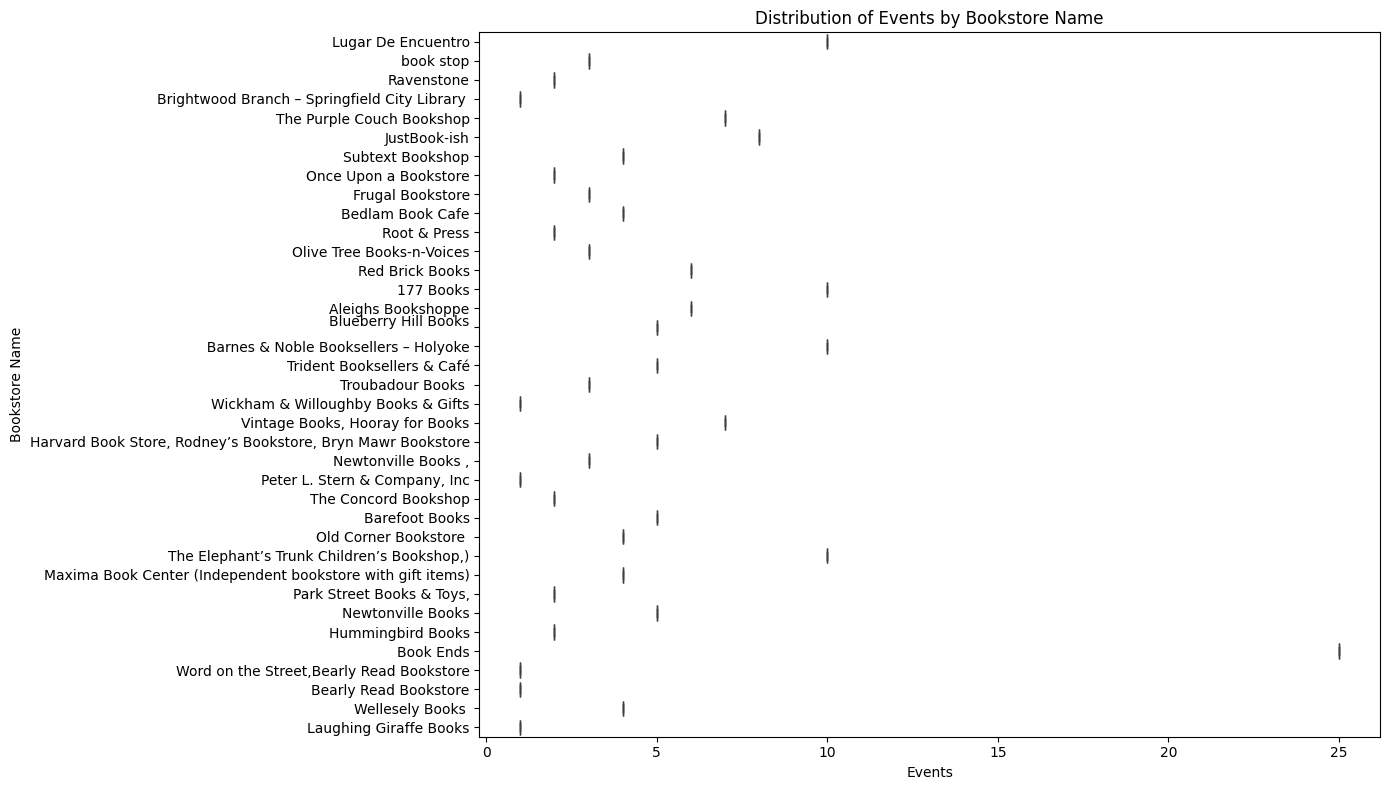

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Clean column names by removing trailing spaces
combined_df.columns = combined_df.columns.str.strip()

# Convert 'events' to numeric, coercing errors to NaN
combined_df['events'] = pd.to_numeric(combined_df['events'], errors='coerce')

# Create a boxplot of 'events' grouped by 'Bookstore Name'
plt.figure(figsize=(14, 8))
sns.boxplot(x='events', y='Bookstore Name', data=combined_df.dropna(subset=['events']))
plt.title('Distribution of Events by Bookstore Name')
plt.xlabel('Events')
plt.ylabel('Bookstore Name')
plt.tight_layout()
plt.show()

This boxplot shows how the number of events varies across different bookstores. It highlights the central tendency and spread of event counts for each bookstore and makes it easy to spot those with unusually high or low activity. A few bookstores appear to host significantly more events than others, suggesting potential hubs of community engagement or larger event spaces.

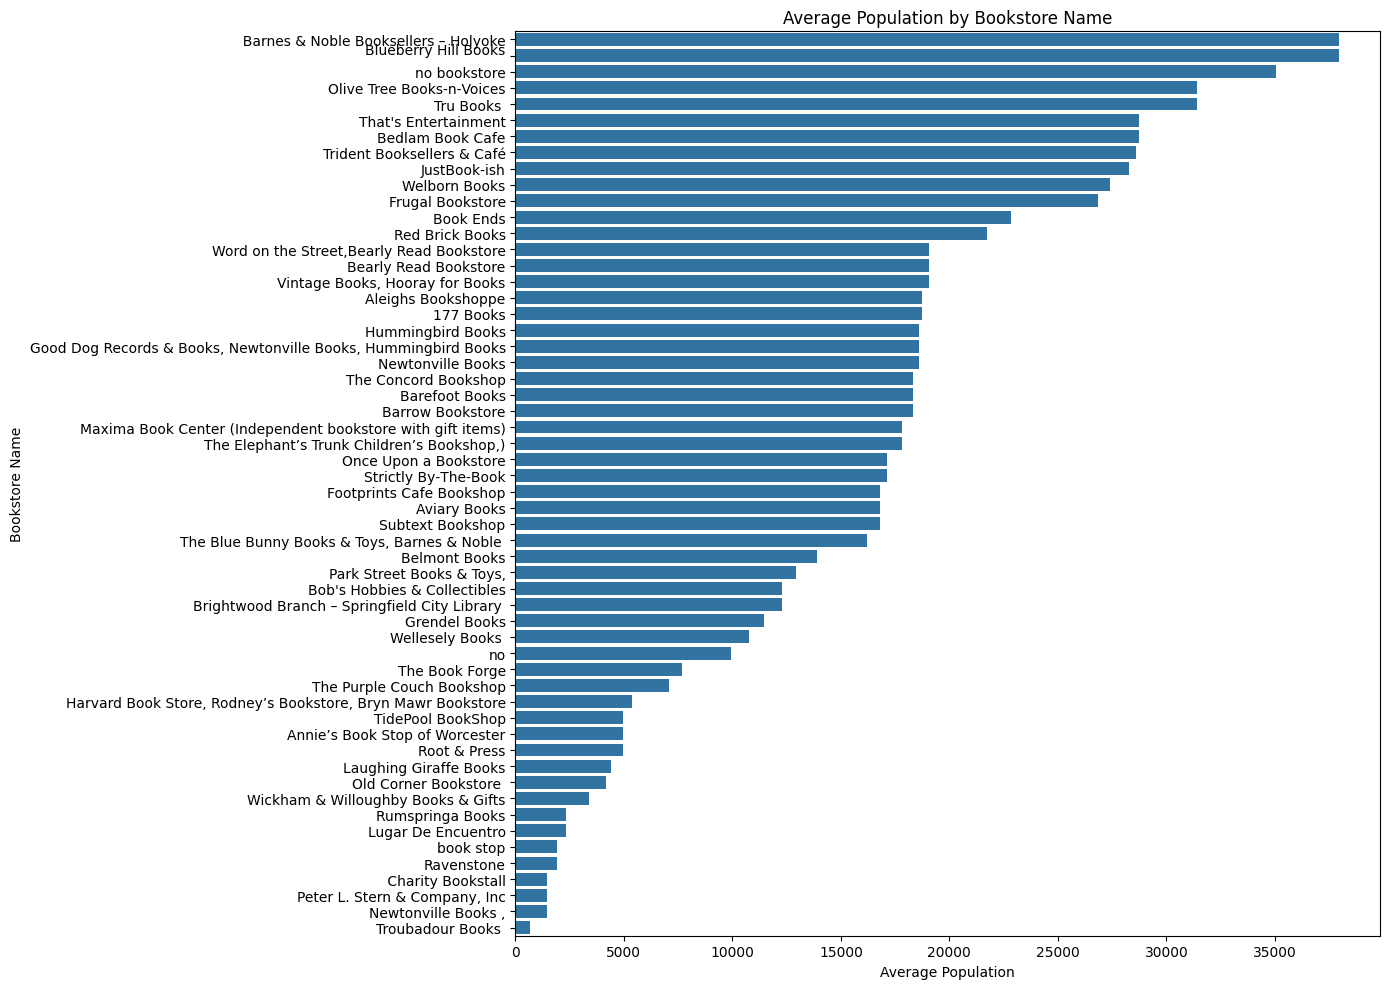


Average Population and ZIP Code by Bookstore Name:


,Bookstore Name,Average_Population,ZIP
0,Barnes & Noble Booksellers – Holyoke,37949.000000,01040
11,Blueberry Hill Books\n,37949.000000,01040
55,no bookstore,35061.000000,02637
28,Olive Tree Books‑n‑Voices,31418.000000,01109
47,Tru Books,31418.000000,01109
38,That's Entertainment,28719.000000,01610
9,Bedlam Book Cafe,28719.000000,01610
45,Trident Booksellers & Café,28621.000000,02115
21,JustBook‑ish,28298.000000,02121
49,Welborn Books,27409.000000,01108


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Clean column names by removing trailing spaces
combined_df.columns = combined_df.columns.str.strip()

# Convert 'Population' to numeric, coercing errors to NaN
combined_df['Population'] = pd.to_numeric(combined_df['Population'], errors='coerce')

# Calculate the average population and get the first ZIP code for each bookstore (assuming consistent ZIP codes for a bookstore)
# If a bookstore spans multiple ZIP codes, this will only show one.
average_population_by_bookstore = combined_df.groupby('Bookstore Name').agg(
    Average_Population=('Population', 'mean'),
    ZIP=('ZIP', 'first')  # Get the first ZIP code for each bookstore
).reset_index()

# Sort by average population for better visualization
average_population_by_bookstore = average_population_by_bookstore.sort_values(by='Average_Population', ascending=False)

# Create a bar plot of average population by bookstore name
plt.figure(figsize=(14, 10))
sns.barplot(x='Average_Population', y='Bookstore Name', data=average_population_by_bookstore)
plt.title('Average Population by Bookstore Name')
plt.xlabel('Average Population')
plt.ylabel('Bookstore Name')
plt.tight_layout()
plt.show()

# Display the dataframe with average population and ZIP code
print("\nAverage Population and ZIP Code by Bookstore Name:")
display(average_population_by_bookstore)

In this section, we analyzed the average ZIP code population around each bookstore. The bar plot shows which bookstores are located in densely or sparsely populated areas. This can help us understand demand and accessibility: for instance, bookstores in high-population ZIPs might have more foot traffic or a broader customer base. Displaying the ZIP codes alongside the average population also helps in targeting specific regions for marketing or expansion decisions.

# Correlation

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import itertools

# Select only numeric columns
numeric_cols = combined_df.select_dtypes(include=['number']).columns

# Generate all unique pairs of numeric columns
column_pairs = list(itertools.combinations(numeric_cols, 2))

print(f"Calculating correlation, R-squared, and MSE for {len(column_pairs)} pairs of numeric columns:")

for col1, col2 in column_pairs:
    print(f"\nAnalyzing relationship between '{col1}' and '{col2}':")

    # Drop rows with NaN in either column
    df_cleaned = combined_df.dropna(subset=[col1, col2]).copy()

    if df_cleaned.empty:
        print(f"  Not enough data to analyze the relationship between '{col1}' and '{col2}'.")
        continue

    # Calculate correlation
    correlation_value = df_cleaned[col1].corr(df_cleaned[col2])
    print(f"  Correlation: {correlation_value:.2f}")

    # Perform linear regression if there's more than one unique value in both columns
    if df_cleaned[col1].nunique() > 1 and df_cleaned[col2].nunique() > 1:
        X = df_cleaned[col1].values.reshape(-1, 1)
        y = df_cleaned[col2].values

        model = LinearRegression()
        model.fit(X, y)

        y_pred = model.predict(X)

        # Calculate R-squared
        r2 = r2_score(y, y_pred)

        # Calculate Mean Squared Error (MSE)
        mse = mean_squared_error(y, y_pred)

        print(f"  R-squared: {r2:.2f}")
        print(f"  Mean Squared Error (MSE): {mse:.2f}")
    else:
        print(f"  Not enough variation in data to perform linear regression between '{col1}' and '{col2}'.")

print("\nFinished calculating metrics for all pairs.")

Calculating correlation, R-squared, and MSE for 6 pairs of numeric columns:

Analyzing relationship between 'Population' and 'Median Income':
  Correlation: -0.12
  R-squared: 0.02
  Mean Squared Error (MSE): 7550737550.51

Analyzing relationship between 'Population' and 'square feet':
  Correlation: 0.09
  R-squared: 0.01
  Mean Squared Error (MSE): 667011.69

Analyzing relationship between 'Population' and 'events':
  Correlation: 0.29
  R-squared: 0.08
  Mean Squared Error (MSE): 17.14

Analyzing relationship between 'Median Income' and 'square feet':
  Correlation: 0.05
  R-squared: 0.00
  Mean Squared Error (MSE): 670654.21

Analyzing relationship between 'Median Income' and 'events':
  Correlation: -0.05
  R-squared: 0.00
  Mean Squared Error (MSE): 18.67

Analyzing relationship between 'square feet' and 'events':
  Correlation: -0.09
  R-squared: 0.01
  Mean Squared Error (MSE): 18.99

Finished calculating metrics for all pairs.


We began by selecting only the numeric columns in the dataset and then generated all possible unique pairs for comparison. This setup helps us explore every potential bivariate relationship using correlation, R-squared, and MSE values.

For each pair of numeric columns, we calculated their correlation coefficient to measure the strength and direction of the linear relationship. If both columns had more than one unique value, we also applied linear regression to derive R-squared and Mean Squared Error (MSE). This comprehensive approach helps us statistically evaluate how closely two variables are related.

The output reveals that most relationships between numeric features are weak or negligible. The highest observed correlation was 0.29 between Population and events, which still indicates only a mild association. All other correlations hover near zero, with low R-squared values, confirming that none of the variables strongly predict one another.



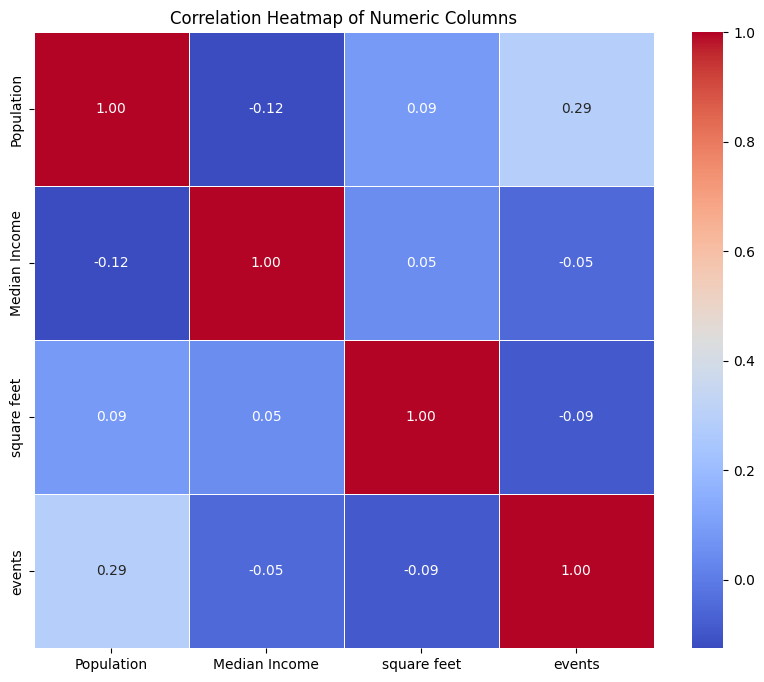

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numeric columns
numeric_df = combined_df.select_dtypes(include=['number'])

# Compute the correlation matrix
correlation_matrix = numeric_df.corr()

# Generate the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Columns')
plt.show()

To visually summarize the strength of relationships between all numeric variables, we created a correlation heatmap. The values and colors clearly show that most variables have weak correlations. The only mildly positive correlation was seen between Population and events (0.29), which aligns with our earlier analysis.

# Multivariate Analysis

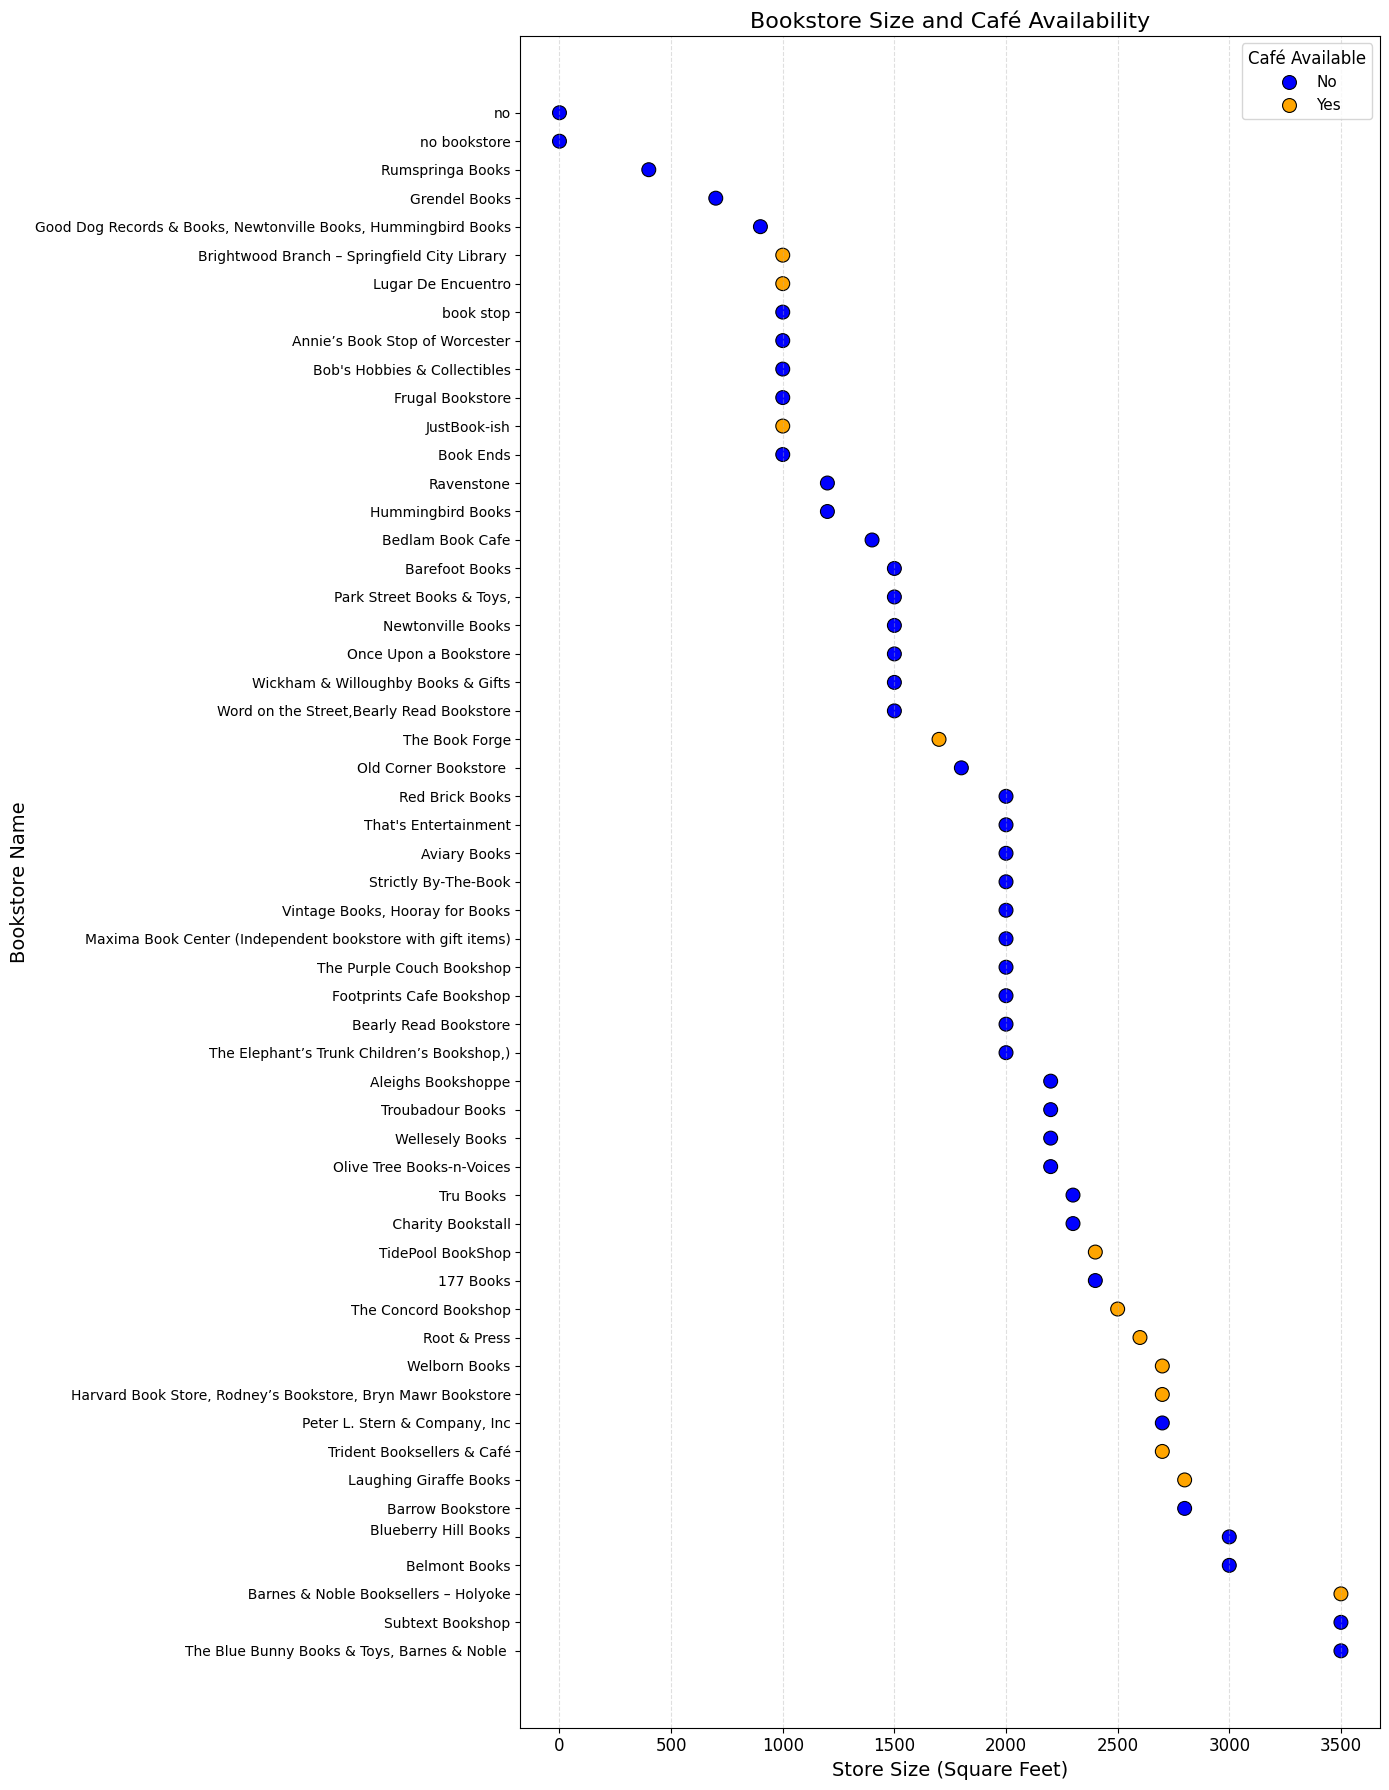

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Clean column names
combined_df.columns = combined_df.columns.str.strip()

# Convert 'square feet' to numeric
combined_df['square feet'] = pd.to_numeric(combined_df['square feet'], errors='coerce')

# Standardize 'café' values
combined_df['café'] = (
    combined_df['café']
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({'yes': 'Yes', 'no': 'No'})
)

# Drop rows with missing required data
df_cleaned = combined_df.dropna(subset=['square feet', 'café', 'Bookstore Name']).copy()

# Sort bookstores for clearer y-axis
df_cleaned = df_cleaned.sort_values(by='square feet', ascending=True)

# Set plot size
plt.figure(figsize=(14, 18))

# Improved scatterplot
sns.scatterplot(
    data=df_cleaned,
    x='square feet',
    y='Bookstore Name',
    hue='café',
    palette={'Yes': 'orange', 'No': 'blue'},
    s=100,
    edgecolor='black'
)

# Title and axis formatting
plt.title('Bookstore Size and Café Availability', fontsize=16)
plt.xlabel('Store Size (Square Feet)', fontsize=14)
plt.ylabel('Bookstore Name', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=10)

# Better legend formatting
plt.legend(title='Café Available', title_fontsize=12, fontsize=11)

# Optional: add light grid
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()



This explains on avarage bookstores with more (>1000) Square feet have a higher chance of having a cafe comapred to those who have a low (<1000) square feet have fewer chance to have a cafe.

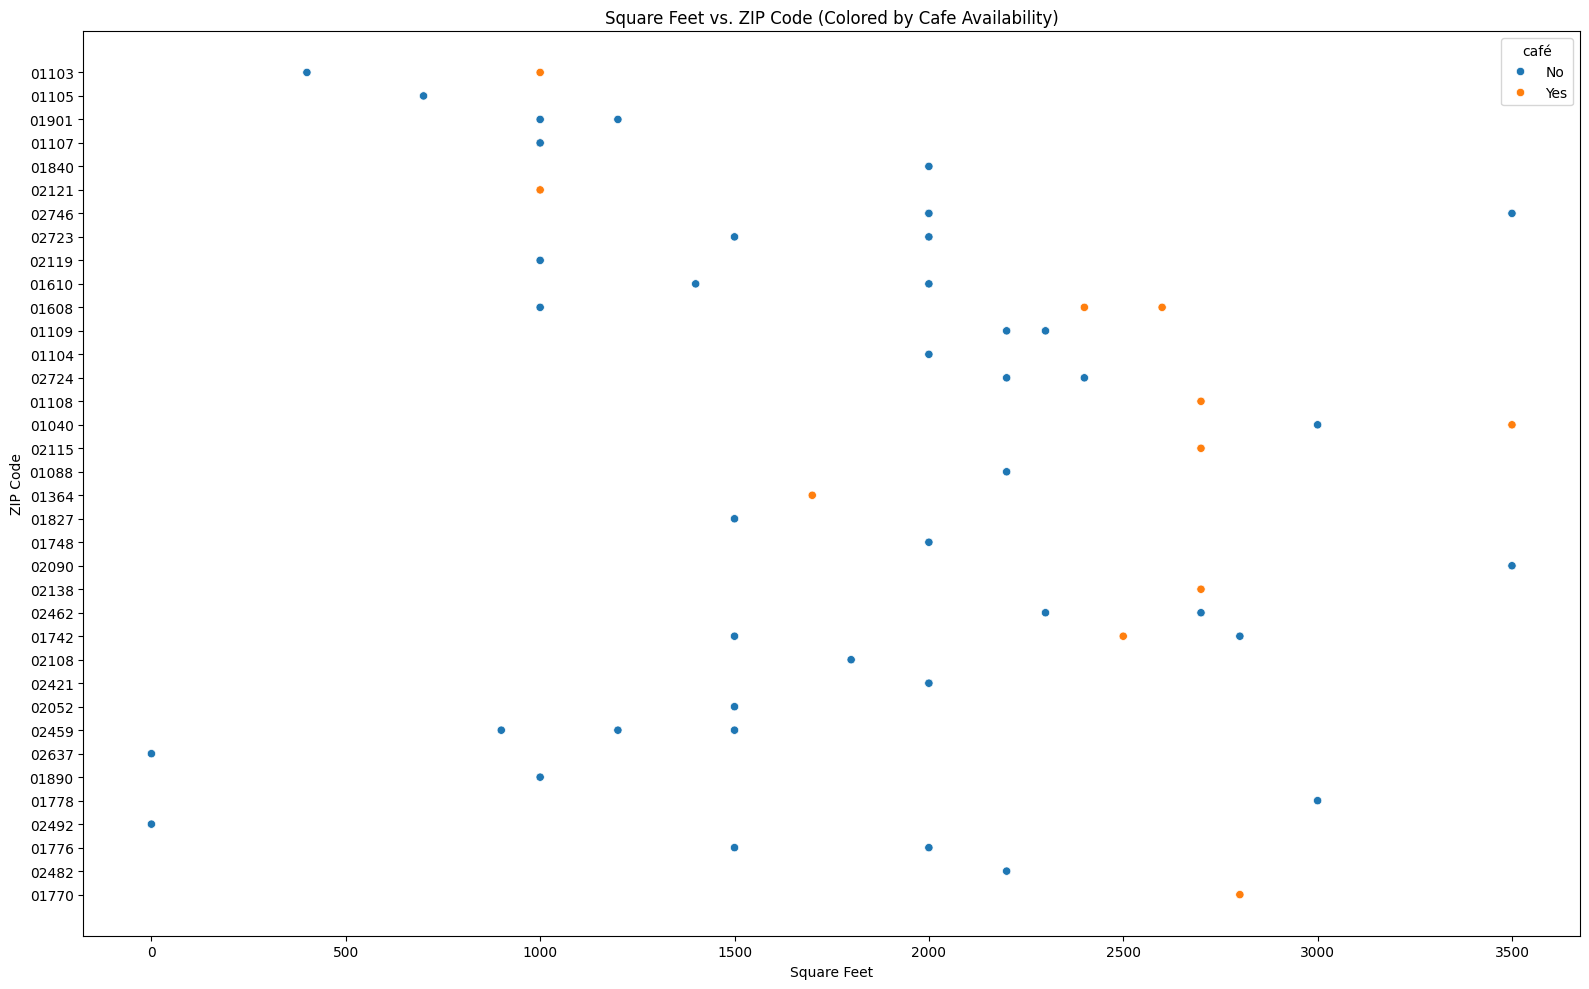

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Clean column names by removing trailing spaces
combined_df.columns = combined_df.columns.str.strip()

# Convert 'ZIP' to string/categorical for plotting
combined_df['ZIP'] = combined_df['ZIP'].astype(str)

# Convert 'square feet' to numeric, coercing errors to NaN
combined_df['square feet'] = pd.to_numeric(combined_df['square feet'], errors='coerce')

# Convert 'café' to a categorical type for plotting
# Assuming 'yes' and 'no' are the primary values, handle potential variations
combined_df['café'] = combined_df['café'].astype(str).str.lower().replace({'yes': 'Yes', 'no': 'No', 'nan': 'Unknown'})

# Drop rows with NaN in the selected columns for plotting
df_cleaned = combined_df.dropna(subset=['ZIP', 'square feet', 'café']).copy()

plt.figure(figsize=(16, 10))
sns.scatterplot(x='square feet', y='ZIP', hue='café', data=df_cleaned)
plt.title('Square Feet vs. ZIP Code (Colored by Cafe Availability)')
plt.xlabel('Square Feet')
plt.ylabel('ZIP Code')
plt.tight_layout()
plt.show()

It explains that Zipcodes with more (>1000) Square feet have a higher chance of having a cafe comapred to those who have a low (<1000) square feet have fewer chance to have a cafe.

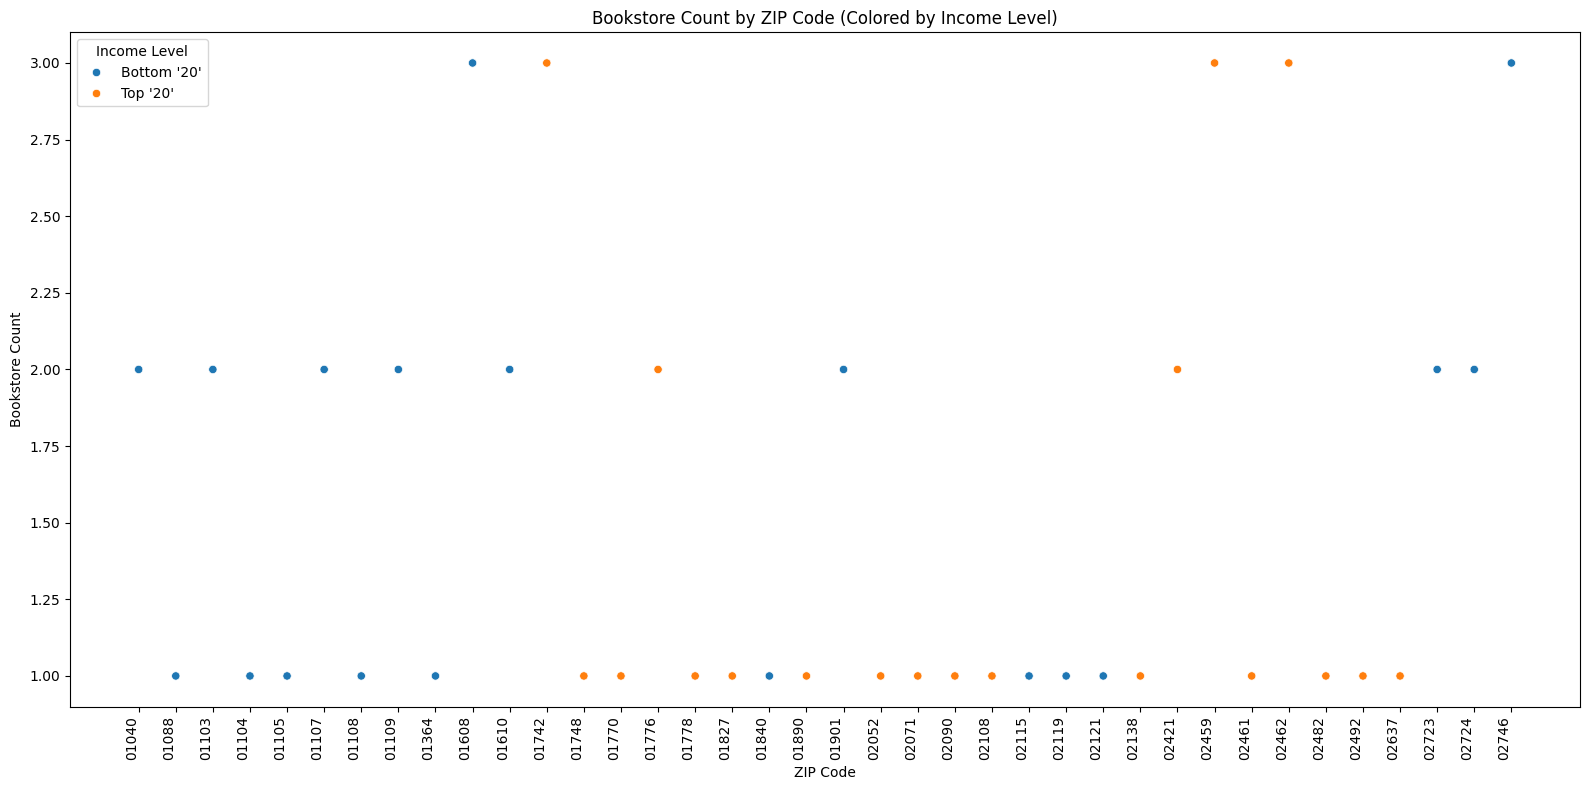

In [ ]:
# Clean column names by removing trailing spaces
combined_df.columns = combined_df.columns.str.strip()

# Count the number of bookstores in each zip code
bookstore_counts = combined_df.groupby('ZIP')['Bookstore Name'].count().reset_index()
bookstore_counts.columns = ['ZIP', 'Bookstore Count']

# Merge with the original dataframe to get income level for each zip code
# Assuming income level is consistent within a zip code, we can take the first one
zip_income = combined_df[['ZIP', 'Income Level']].drop_duplicates(subset=['ZIP']).copy()

bookstore_count_income = pd.merge(bookstore_counts, zip_income, on='ZIP', how='left')

# Convert 'Bookstore Count' to numeric, coercing errors to NaN
bookstore_count_income['Bookstore Count'] = pd.to_numeric(bookstore_count_income['Bookstore Count'], errors='coerce')

# Drop rows with NaN in the selected columns for plotting
df_cleaned = bookstore_count_income.dropna(subset=['Bookstore Count', 'Income Level']).copy()

plt.figure(figsize=(16, 8))
sns.scatterplot(x='ZIP', y='Bookstore Count', hue='Income Level', data=df_cleaned)
plt.title('Bookstore Count by ZIP Code (Colored by Income Level)')
plt.xlabel('ZIP Code')
plt.ylabel('Bookstore Count')
plt.xticks(rotation=90, ha='right') # Rotate x-axis labels for readability
plt.tight_layout()
plt.show()

This explains which zipcodes have the highest income level and how many  bookstores per zipcode. There is more bookstores for the bottom 20 zipcode that is concentrated into one zipcode then the top 20 which ussually consist of 1 bookstore.

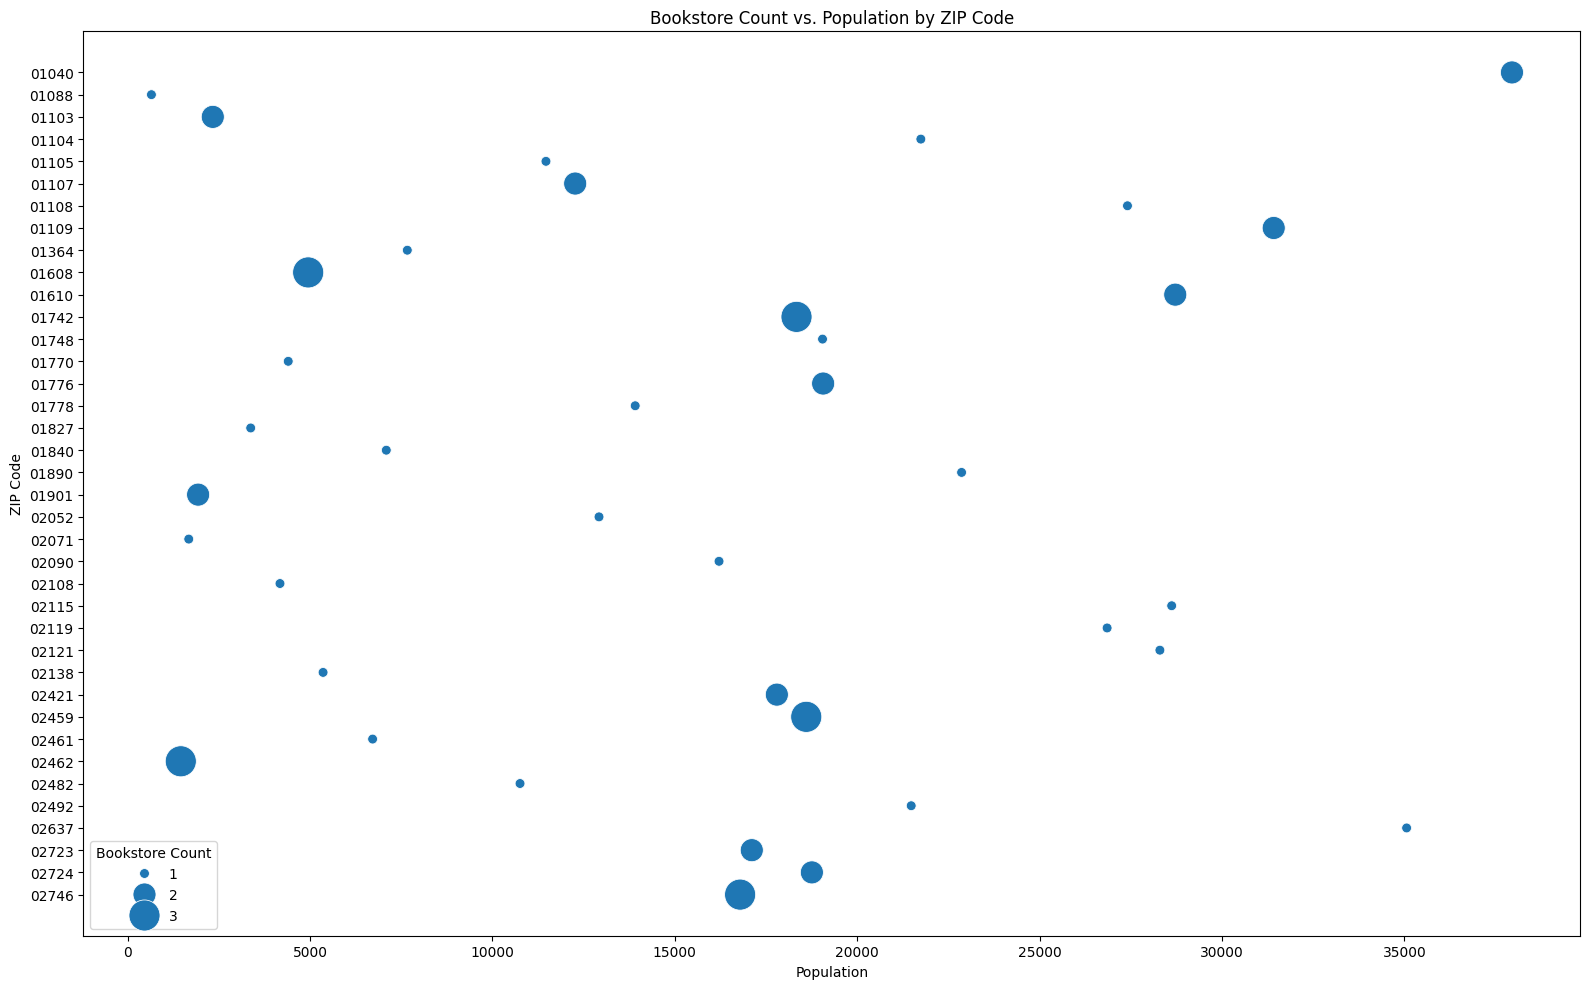

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Clean column names by removing trailing spaces
combined_df.columns = combined_df.columns.str.strip()

# Convert 'ZIP' to string/categorical
combined_df['ZIP'] = combined_df['ZIP'].astype(str)

# Convert 'Population' to numeric, coercing errors to NaN
combined_df['Population'] = pd.to_numeric(combined_df['Population'], errors='coerce')

# Count the number of bookstores in each zip code
bookstore_counts = combined_df.groupby('ZIP')['Bookstore Name'].count().reset_index()
bookstore_counts.columns = ['ZIP', 'Bookstore Count']

# Merge with the original dataframe to get population for each zip code
# Taking the mean of population for each zip code as it might be repeated
zip_population = combined_df.groupby('ZIP')['Population'].mean().reset_index()


bookstore_count_population = pd.merge(bookstore_counts, zip_population, on='ZIP', how='left')


# Drop rows with NaN in the selected columns for plotting
df_cleaned = bookstore_count_population.dropna(subset=['ZIP', 'Population', 'Bookstore Count']).copy()


plt.figure(figsize=(16, 10))
sns.scatterplot(x='Population', y='ZIP', size='Bookstore Count', data=df_cleaned, sizes=(50, 500))
plt.title('Bookstore Count vs. Population by ZIP Code')
plt.xlabel('Population')
plt.ylabel('ZIP Code')
plt.tight_layout()
plt.show()

This explains the correlation between population and the amount of bookstores. In this graph there is negative or no correlation with population and amount of bookstores. With it being all over the place and not having patterns.

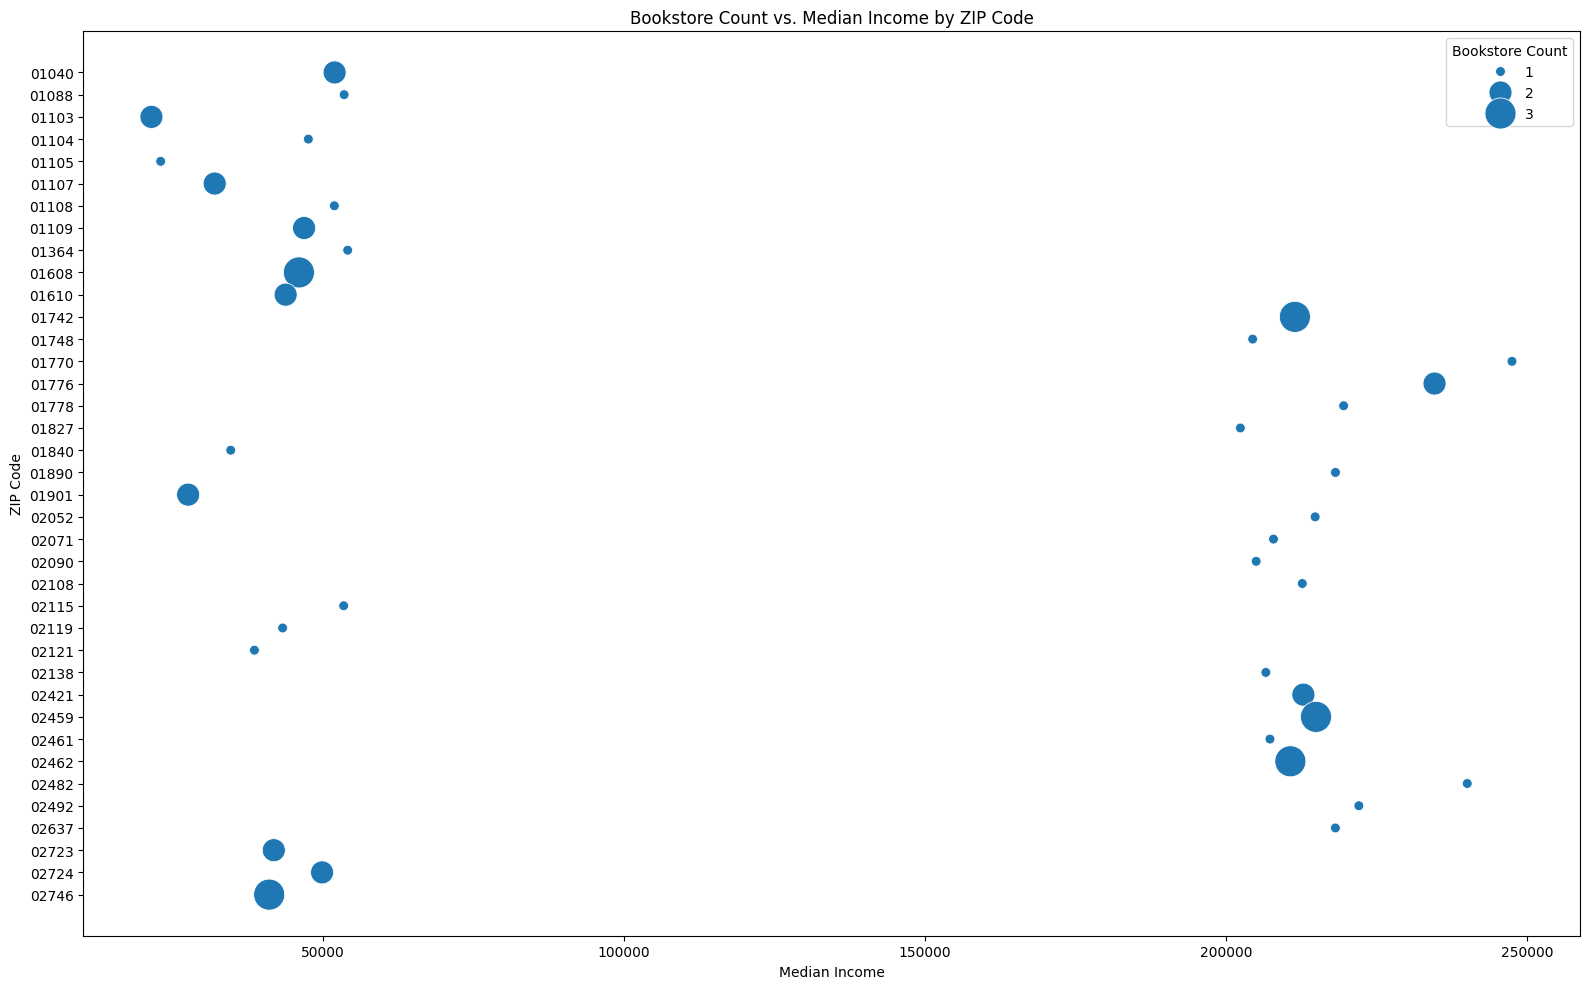

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Clean column names by removing trailing spaces
combined_df.columns = combined_df.columns.str.strip()

# Convert 'ZIP' to string/categorical
combined_df['ZIP'] = combined_df['ZIP'].astype(str)

# Convert 'Median Income' to numeric, coercing errors to NaN
combined_df['Median Income'] = pd.to_numeric(combined_df['Median Income'], errors='coerce')

# Count the number of bookstores in each zip code
bookstore_counts = combined_df.groupby('ZIP')['Bookstore Name'].count().reset_index()
bookstore_counts.columns = ['ZIP', 'Bookstore Count']

# Merge with the original dataframe to get median income for each zip code
# Taking the mean of median income for each zip code as it might be repeated
zip_median_income = combined_df.groupby('ZIP')['Median Income'].mean().reset_index()


bookstore_count_median_income = pd.merge(bookstore_counts, zip_median_income, on='ZIP', how='left')


# Drop rows with NaN in the selected columns for plotting
df_cleaned = bookstore_count_median_income.dropna(subset=['ZIP', 'Median Income', 'Bookstore Count']).copy()


plt.figure(figsize=(16, 10))
sns.scatterplot(x='Median Income', y='ZIP', size='Bookstore Count', data=df_cleaned, sizes=(50, 500))
plt.title('Bookstore Count vs. Median Income by ZIP Code')
plt.xlabel('Median Income')
plt.ylabel('ZIP Code')
plt.tight_layout()
plt.show()

In this graph it explains the bookstore count based on income distribution. There is a bimodal distribution. The lower income has bookstores due to them usually living in the inner cities where shops are common. For the higher income it is their literacy rate and purchasing power which attracts business.



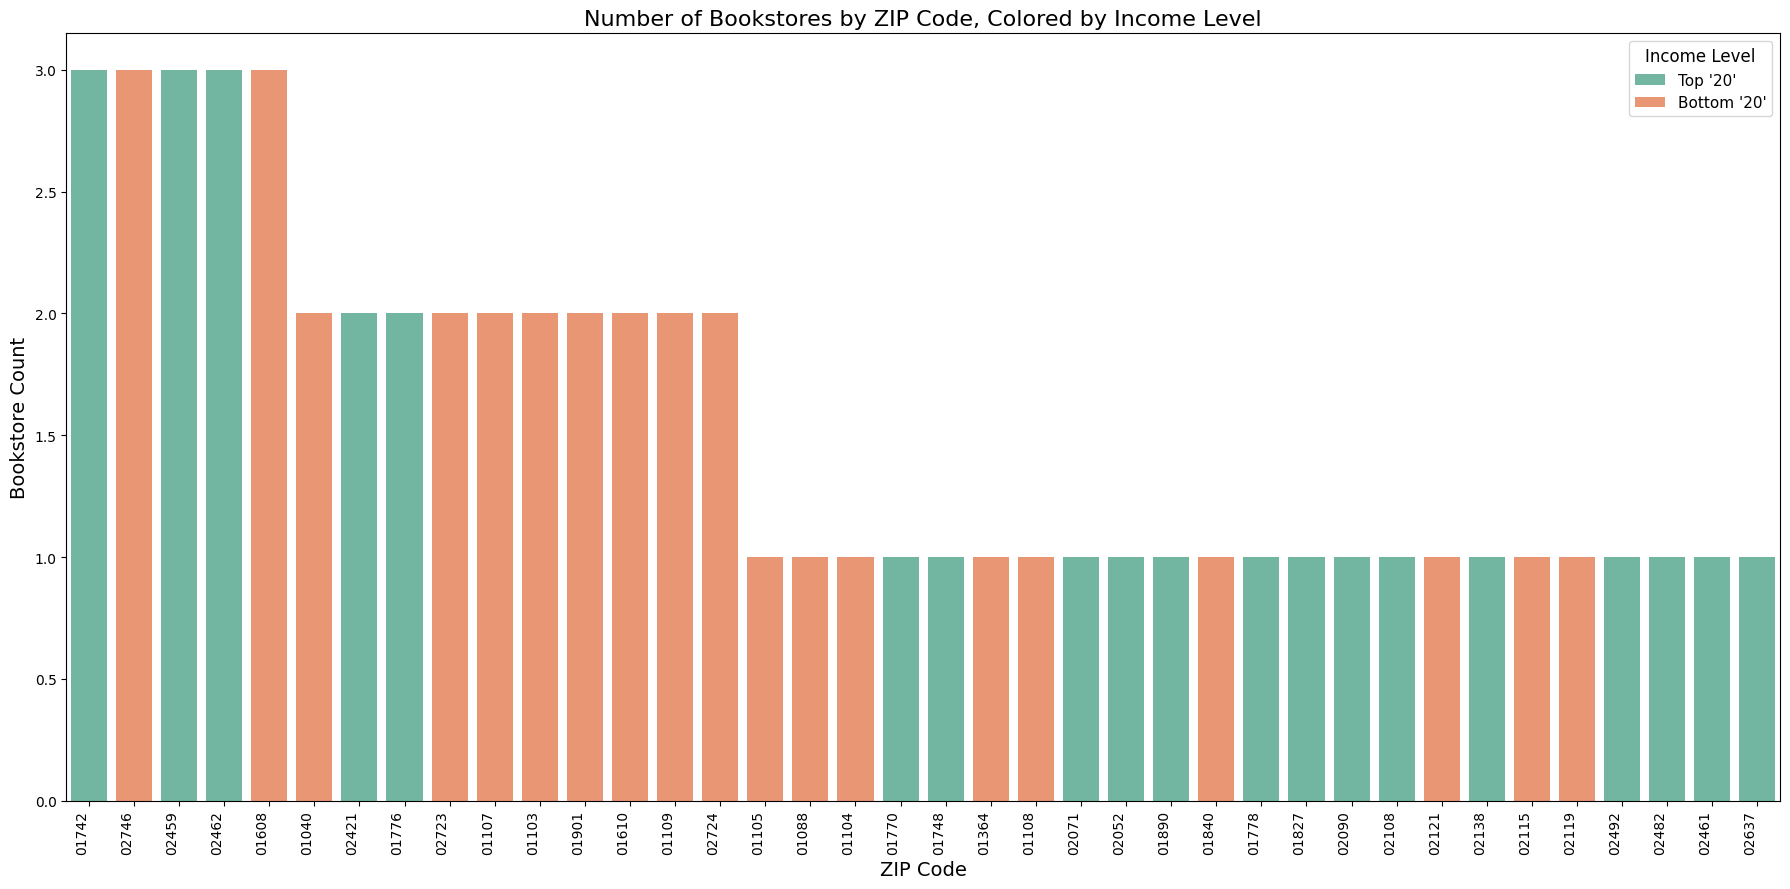

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Clean column names
combined_df.columns = combined_df.columns.str.strip()

# Count bookstores per ZIP code
bookstore_counts = combined_df.groupby('ZIP')['Bookstore Name'].count().reset_index()
bookstore_counts.columns = ['ZIP', 'Bookstore Count']

# Get unique ZIP - Income Level mapping
zip_income = combined_df[['ZIP', 'Income Level']].drop_duplicates(subset=['ZIP'])

# Merge bookstore counts with income levels
bookstore_count_income = pd.merge(bookstore_counts, zip_income, on='ZIP', how='left')

# Drop missing values
df_cleaned = bookstore_count_income.dropna(subset=['Bookstore Count', 'Income Level']).copy()

# Sort by Bookstore Count descending for better visualization
df_cleaned = df_cleaned.sort_values('Bookstore Count', ascending=False)

plt.figure(figsize=(18, 9))

# Create a barplot with ZIP codes ordered by bookstore count
sns.barplot(
    data=df_cleaned,
    x='ZIP',
    y='Bookstore Count',
    hue='Income Level',
    palette='Set2',
    dodge=False  # stack colors instead of side-by-side (better for categorical income levels)
)

plt.title('Number of Bookstores by ZIP Code, Colored by Income Level', fontsize=16)
plt.xlabel('ZIP Code', fontsize=14)
plt.ylabel('Bookstore Count', fontsize=14)
plt.xticks(rotation=90, ha='right')
plt.legend(title='Income Level', title_fontsize=12, fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()


This explains which zipcodes have the highest income level and how many  bookstores per zipcode. There is more bookstores for the bottom 20 zipcode that is concentrated into one zipcode then the top 20 which ussually consist of 1 bookstore.

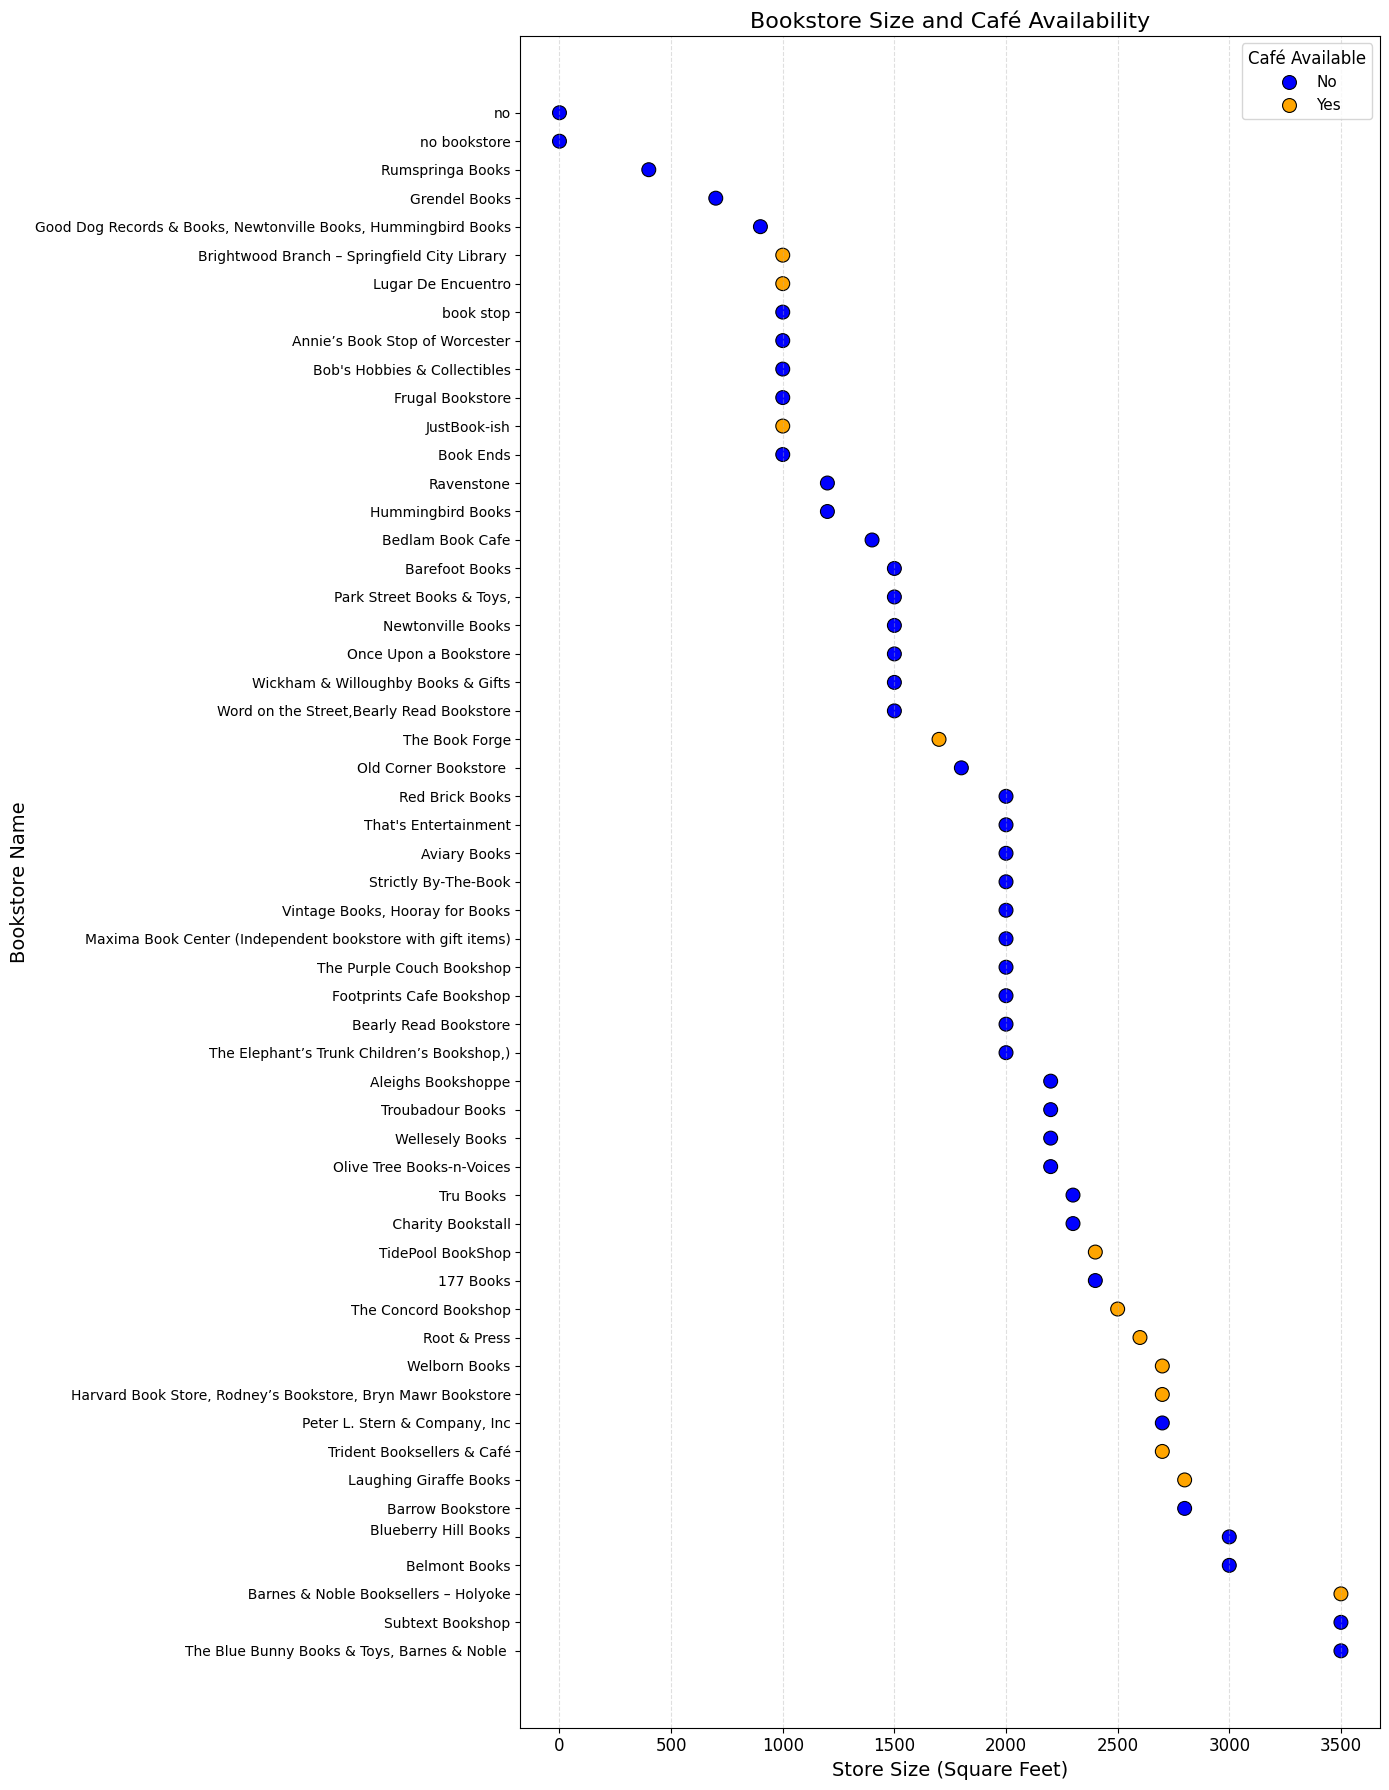

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Clean column names
combined_df.columns = combined_df.columns.str.strip()

# Convert 'square feet' to numeric
combined_df['square feet'] = pd.to_numeric(combined_df['square feet'], errors='coerce')

# Standardize 'café' values
combined_df['café'] = (
    combined_df['café']
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({'yes': 'Yes', 'no': 'No'})
)

# Drop rows with missing required data
df_cleaned = combined_df.dropna(subset=['square feet', 'café', 'Bookstore Name']).copy()

# Sort bookstores for clearer y-axis
df_cleaned = df_cleaned.sort_values(by='square feet', ascending=True)

# Set plot size
plt.figure(figsize=(14, 18))

# Improved scatterplot
sns.scatterplot(
    data=df_cleaned,
    x='square feet',
    y='Bookstore Name',
    hue='café',
    palette={'Yes': 'orange', 'No': 'blue'},
    s=100,
    edgecolor='black'
)

# Title and axis formatting
plt.title('Bookstore Size and Café Availability', fontsize=16)
plt.xlabel('Store Size (Square Feet)', fontsize=14)
plt.ylabel('Bookstore Name', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=10)

# Better legend formatting
plt.legend(title='Café Available', title_fontsize=12, fontsize=11)

# Optional: add light grid
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()




This explains on avarage bookstores with more (>1000) Square feet have a higher chance of having a cafe comapred to those who have a low (<1000) square feet have fewer chance to have a cafe.

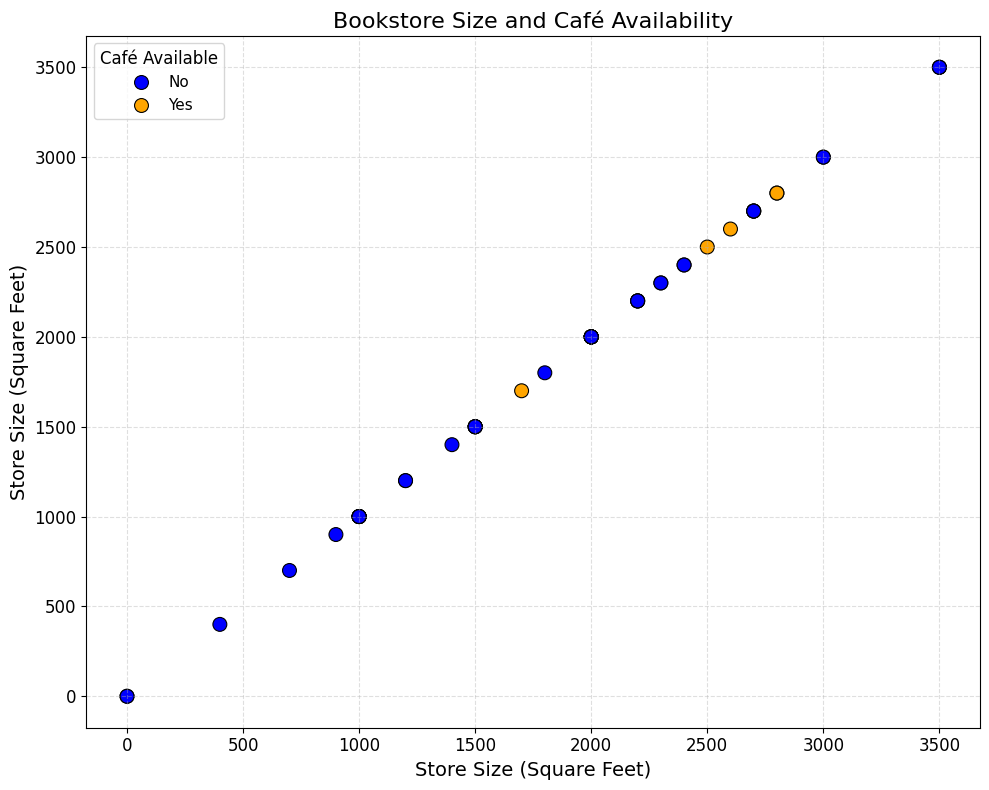

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Clean column names
combined_df.columns = combined_df.columns.str.strip()

# Convert 'square feet' to numeric
combined_df['square feet'] = pd.to_numeric(combined_df['square feet'], errors='coerce')

# Standardize 'café' values
combined_df['café'] = (
    combined_df['café']
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({'yes': 'Yes', 'no': 'No'})
)

# Drop rows with missing required data
df_cleaned = combined_df.dropna(subset=['square feet', 'café']).copy()

# Set plot size
plt.figure(figsize=(10, 8))

# Create a scatterplot
sns.scatterplot(
    data=df_cleaned,
    x='square feet',
    y='square feet',
    hue='café',
    palette={'Yes': 'orange', 'No': 'blue'},
    s=100,
    edgecolor='black'
)

# Title and axis formatting
plt.title('Bookstore Size and Café Availability', fontsize=16)
plt.xlabel('Store Size (Square Feet)', fontsize=14)
plt.ylabel('Store Size (Square Feet)', fontsize=14) # Y-axis is also square feet for visualization of cafe distribution
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Better legend formatting
plt.legend(title='Café Available', title_fontsize=12, fontsize=11)

# Optional: add light grid
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# Hypothesis

## Distribution of Numeric Features

Histograms and boxplots showed that most numerical variables (like square footage, events, population) are right-skewed, suggesting that a few bookstores are significantly larger or host more events than others.

Hypothesis: Bookstores vary widely in characteristics like size and events, which could indicate market segmentation, like local stores or chains.




## Correlation Heatmap

The correlation matrix revealed moderate positive relationships between some features, such as:

square feet and events — suggesting that larger stores tend to host more events.

Hypothesis: Store size positively influences community engagement, possibly due to available space and resources.



## Pairwise Scatter Plots

Scatter plots showed visual clustering and a few outliers, reinforcing the idea that not all bookstores follow the same profile.

Hypothesis: Bookstores may naturally fall into clusters based on operational scale and services offered.




## Boxplots by Bookstore Name

The square footage and event distributions varied considerably by bookstore, indicating that:

Some stores consistently offer more space and host more community events.

Hypothesis: Individual bookstore identity and branding (e.g., community-oriented vs. retail-focused) drive operational decisions.





## Bar Plot of Population by Bookstore

Certain bookstores were located in ZIP codes with significantly higher populations, which might influence customer traffic.

Hypothesis: Bookstores in densely populated areas likely benefit from increased foot traffic and broader community engagement.






## Café Availability vs. Square Footage

Bookstores with cafés tend to be larger in square footage, as seen in the scatterplot colored by café presence.

Hypothesis: Offering a café requires and correlates with more space, potentially increasing customer dwell time and revenue.




## ZIP Code vs. Store Size with Café Indicator

Geographic scatterplots showed that café availability is not evenly distributed across ZIP codes, indicating a potential demographic or regional influence.

Hypothesis: Store amenities like cafés may be influenced by ZIP-level demographics or regional preferences.